# BCSC: Full Feature vs Cancer Association Analysis



In [6]:
# Cell 1: Imports and configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import chi2_contingency


DATA_PATH = Path("risk.csv")
TARGET = "cancer"
WEIGHT = "count"
UNKNOWN_CODE = 9

EXCLUDED_COLUMNS = [
    TARGET,
    "invasive",
    "training",
    WEIGHT,
]

OUTPUT_DIR = Path("BCSC_Full_Feature_Analysis")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Configuration loaded.")
print(f"Data file: {DATA_PATH.resolve()}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

Configuration loaded.
Data file: D:\depi pro\BCSC Risk Estimation anl\EDA_data_set\risk.csv
Output directory: D:\depi pro\BCSC Risk Estimation anl\EDA_data_set\BCSC_Full_Feature_Analysis


In [7]:
# Cell 2: Load and validate the dataset

df = pd.read_csv(DATA_PATH)

required_columns = [TARGET, WEIGHT]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df[WEIGHT] = pd.to_numeric(df[WEIGHT], errors="coerce")
    
df = df[df[TARGET].isin([0, 1])].copy()

if df[WEIGHT].isna().any() or (df[WEIGHT] <= 0).any():
    raise ValueError("Invalid count values detected.")
if not np.allclose(df[WEIGHT], df[WEIGHT].round()):
    raise ValueError("Count must contain integer frequencies.")

df[WEIGHT] = df[WEIGHT].astype("int64")
FEATURES = [column for column in df.columns if column not in EXCLUDED_COLUMNS]

print("=" * 70)
print("BCSC FULL FEATURE ASSOCIATION ANALYSIS")
print("=" * 70)
print(f"Dataset shape: {df.shape}")
print(f"Total weighted observations: {df[WEIGHT].sum():,}")
print(f"Target: {TARGET}")
print(f"Features detected: {len(FEATURES)}")
print(FEATURES)

BCSC FULL FEATURE ASSOCIATION ANALYSIS
Dataset shape: (280660, 16)
Total weighted observations: 2,392,998
Target: cancer
Features detected: 12
['menopaus', 'agegrp', 'density', 'race', 'Hispanic', 'bmi', 'agefirst', 'nrelbc', 'brstproc', 'lastmamm', 'surgmeno', 'hrt']


In [8]:
# Cell 3: Statistical helper functions

def weighted_wilson_interval(successes, total, z=1.96):
    """Return a Wilson confidence interval for weighted binomial data."""
    if total <= 0:
        return np.nan, np.nan

    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    margin = (
        z * np.sqrt(
            proportion * (1 - proportion) / total
            + z**2 / (4 * total**2)
        ) / denominator
    )

    return max(0, center - margin), min(1, center + margin)


def calculate_cramers_v(contingency):
    """Return standard V, p-value, and bias-corrected Cramer's V."""
    observed = contingency.to_numpy(dtype=float)
    total = observed.sum()
    rows, columns = observed.shape

    if total <= 1 or min(rows, columns) < 2:
        return np.nan, np.nan, np.nan

    chi2, p_value, _, _ = chi2_contingency(observed, correction=False)
    phi_squared = chi2 / total
    standard_v = np.sqrt(phi_squared / min(rows - 1, columns - 1))

    corrected_phi_squared = max(
        0,
        phi_squared - ((columns - 1) * (rows - 1)) / (total - 1),
    )
    corrected_rows = rows - ((rows - 1) ** 2) / (total - 1)
    corrected_columns = columns - ((columns - 1) ** 2) / (total - 1)
    denominator = min(corrected_rows - 1, corrected_columns - 1)

    corrected_v = (
        np.sqrt(corrected_phi_squared / denominator)
        if denominator > 0
        else np.nan
    )
    return standard_v, p_value, corrected_v


print("Statistical helper functions are ready.")

Statistical helper functions are ready.


In [9]:
# Cell 4: Calculate the overall cancer rate

total_observations = df[WEIGHT].sum()
total_cancer = df.loc[df[TARGET] == 1, WEIGHT].sum()
overall_cancer_rate = total_cancer / total_observations

print(f"Overall Cancer Rate: {overall_cancer_rate:.4%}")

Overall Cancer Rate: 0.4863%



Analyzing: menopaus
Cramer's V: 0.016274024139612493
Corrected Cramer's V: 0.01626012622994013
P-value: 2.2924706175614513e-129
Excluded percentage: 7.604%

Category Statistics:
Category  No Cancer  Cancer   Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0     566489    1726  568215         0.303758      0.289782      0.318407
       1    1633524    9300 1642824         0.566098      0.554740      0.577687


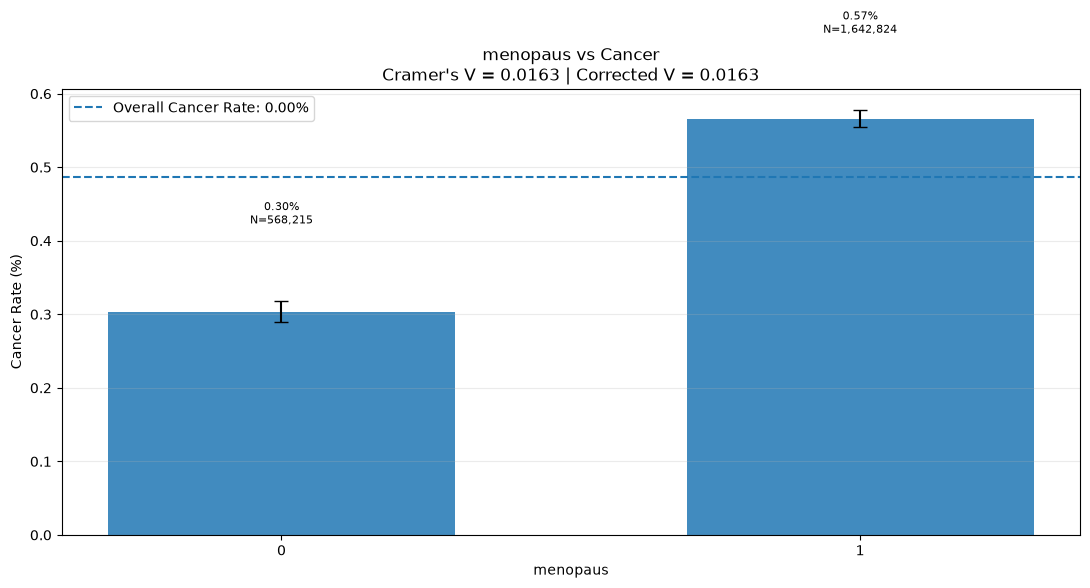


Analyzing: agegrp
Cramer's V: 0.024097018047276035
Corrected Cramer's V: 0.024023064967088403
P-value: 1.7001131429269638e-276
Excluded percentage: 6.064%

Category Statistics:
Category  No Cancer  Cancer  Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       1      42670      88  42758         0.205809      0.167096      0.253470
       2     286633     648 287281         0.225563      0.208868      0.243589
       3     385965    1281 387246         0.330797      0.313198      0.349382
       4     426608    1704 428312         0.397841      0.379428      0.417143
       5     332337    1795 334132         0.537213      0.512989      0.562574
       6     261945    1576 263521         0.598055      0.569328      0.628222
       7     230437    1467 231904         0.632589      0.601128      0.665686
       8     201686    1420 203106         0.699142      0.663826      0.736324
      10      69066     570  69636         0.818542      0.754279      0.888231


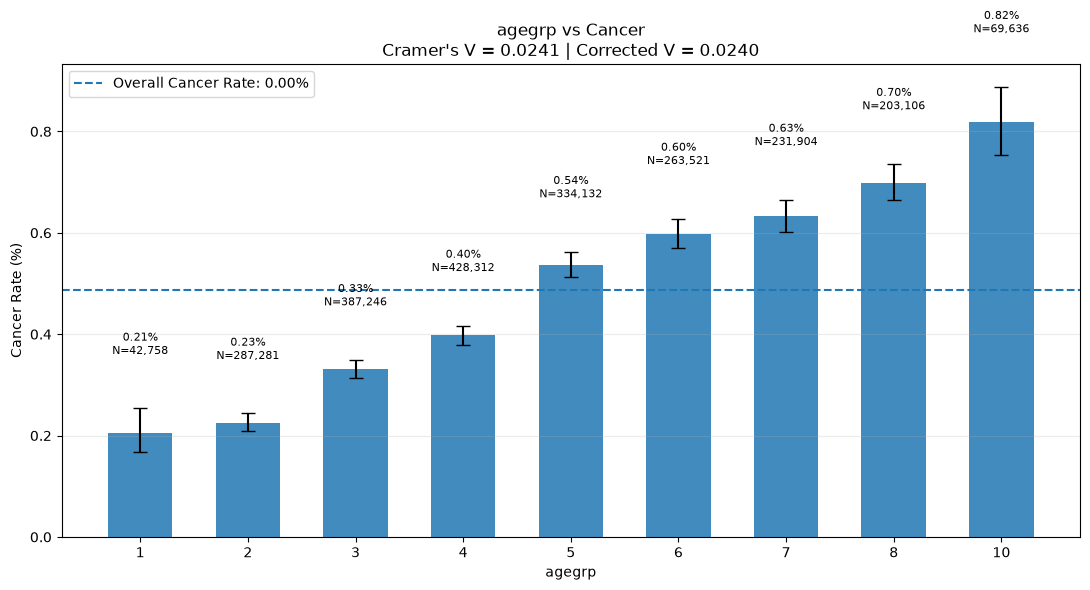


Analyzing: density
Cramer's V: 0.01383711540224905
Corrected Cramer's V: 0.013774699232676118
P-value: 6.25883085288724e-72
Excluded percentage: 27.262%

Category Statistics:
Category  No Cancer  Cancer  Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       1     147881     328 148209         0.221309      0.198641      0.246558
       2     779023    3361 782384         0.429584      0.415334      0.444322
       3     670282    3726 674008         0.552812      0.535391      0.570798
       4     135294     717 136011         0.527163      0.490051      0.567071


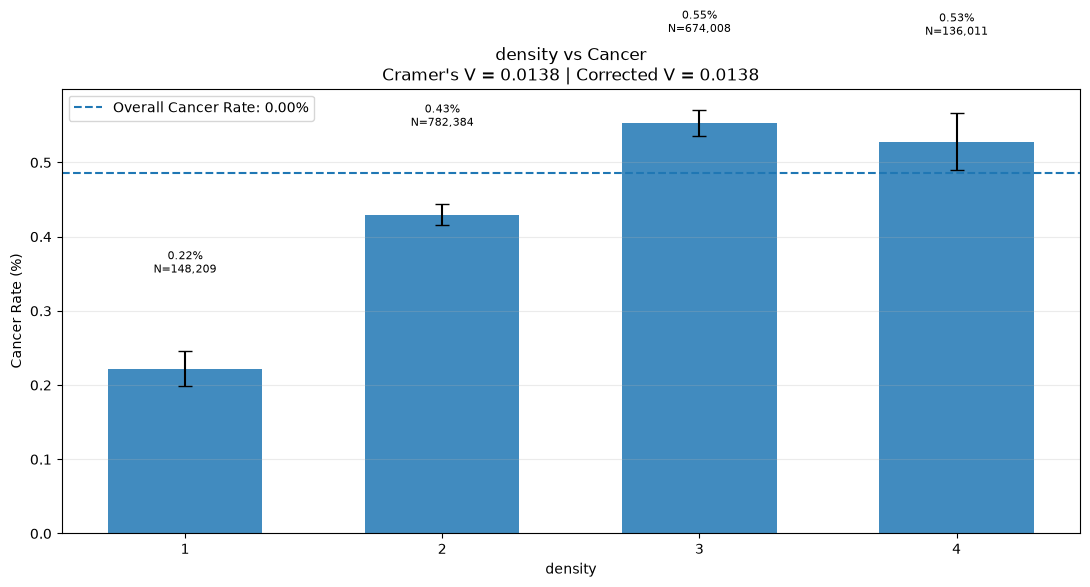


Analyzing: race
Cramer's V: 0.004513675393321179
Corrected Cramer's V: 0.004287934378218654
P-value: 2.668248532995263e-08
Excluded percentage: 15.871%

Category Statistics:
Category  No Cancer  Cancer   Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       1    1729317    8698 1738015         0.500456      0.490074      0.511057
       2     102573     425  102998         0.412629      0.375287      0.453671
       3     120958     576  121534         0.473941      0.436862      0.514151
       4      28277      82   28359         0.289150      0.233031      0.358735
       5      22186     102   22288         0.457645      0.377169      0.555197


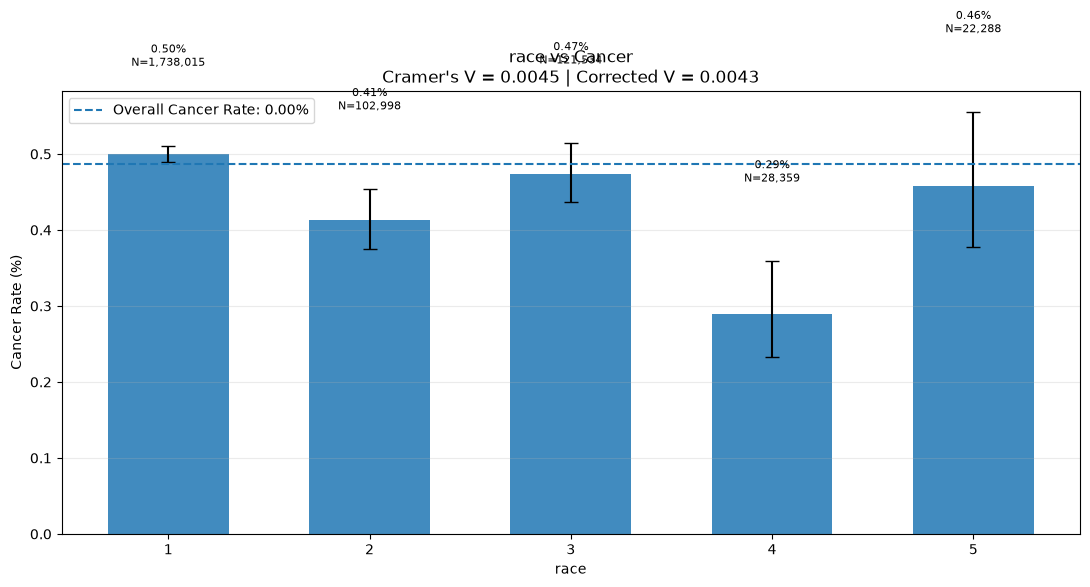


Analyzing: Hispanic
Cramer's V: 0.005126889749518482
Corrected Cramer's V: 0.00507549135447541
P-value: 1.4432939556061375e-12
Excluded percentage: 20.312%

Category Statistics:
Category  No Cancer  Cancer   Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0    1740832    8772 1749604         0.501371      0.491013      0.511946
       1     156756     584  157340         0.371171      0.342310      0.402454


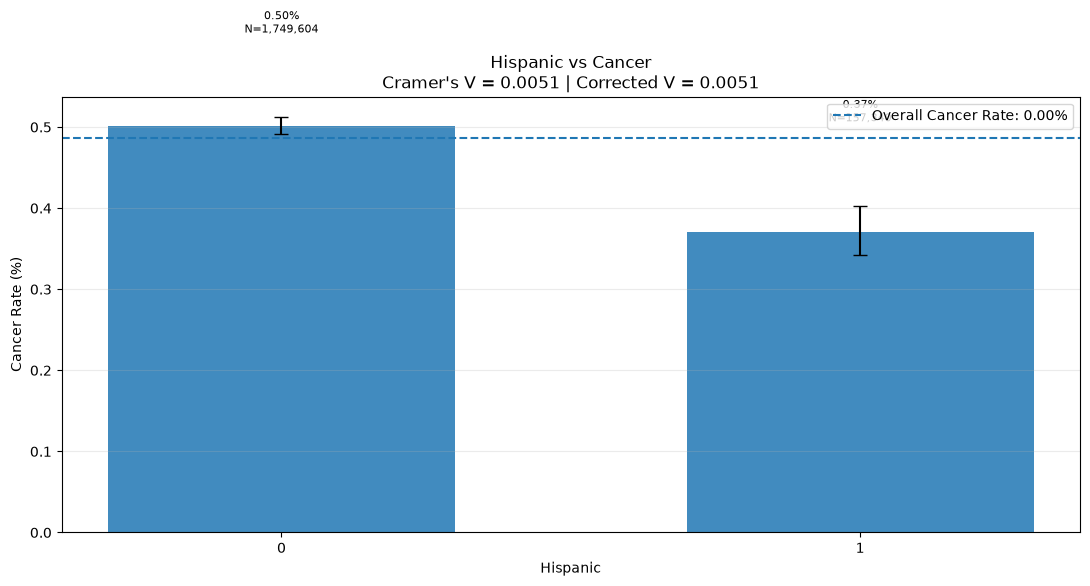


Analyzing: bmi
Cramer's V: 0.0025045413900521398
Corrected Cramer's V: 0.0018531647025879212
P-value: 0.08468908833281542
Excluded percentage: 55.834%

Category Statistics:
Category  No Cancer  Cancer  Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       1     506423    2474 508897         0.486149      0.467409      0.505637
       2     323649    1703 325352         0.523433      0.499215      0.548819
       3     144069     754 144823         0.520636      0.484860      0.559036
       4      77421     400  77821         0.514000      0.466142      0.566743


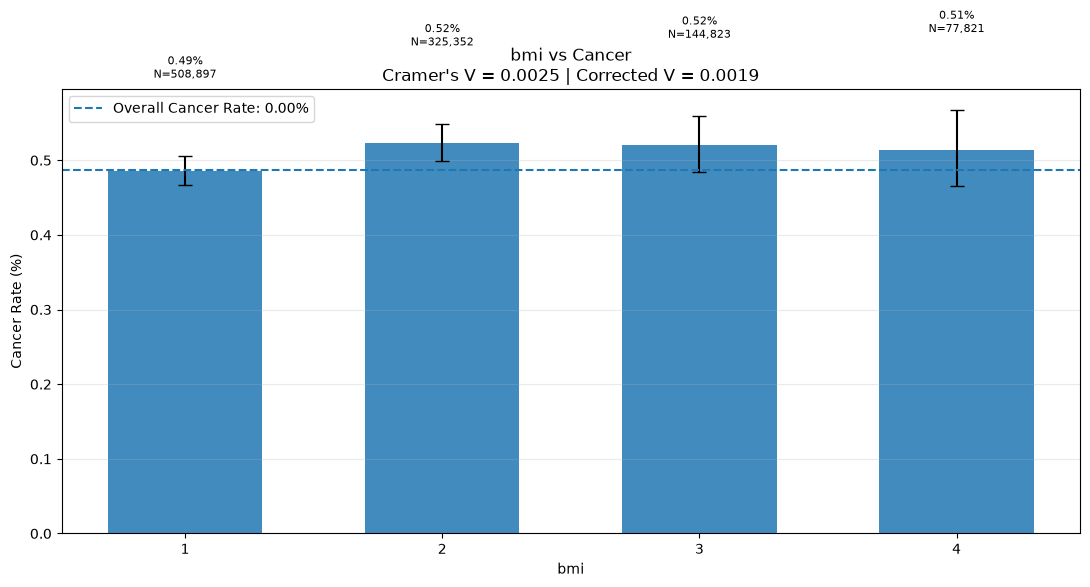


Analyzing: agefirst
Cramer's V: 0.0020543701293207475
Corrected Cramer's V: 0.001530353130456833
P-value: 0.10574149604708455
Excluded percentage: 55.508%

Category Statistics:
Category  No Cancer  Cancer  Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0     718588    3607 722195         0.499450      0.483452      0.515974
       1     140563     724 141287         0.512432      0.476523      0.551033
       2     200141    1081 201222         0.537218      0.506209      0.570115


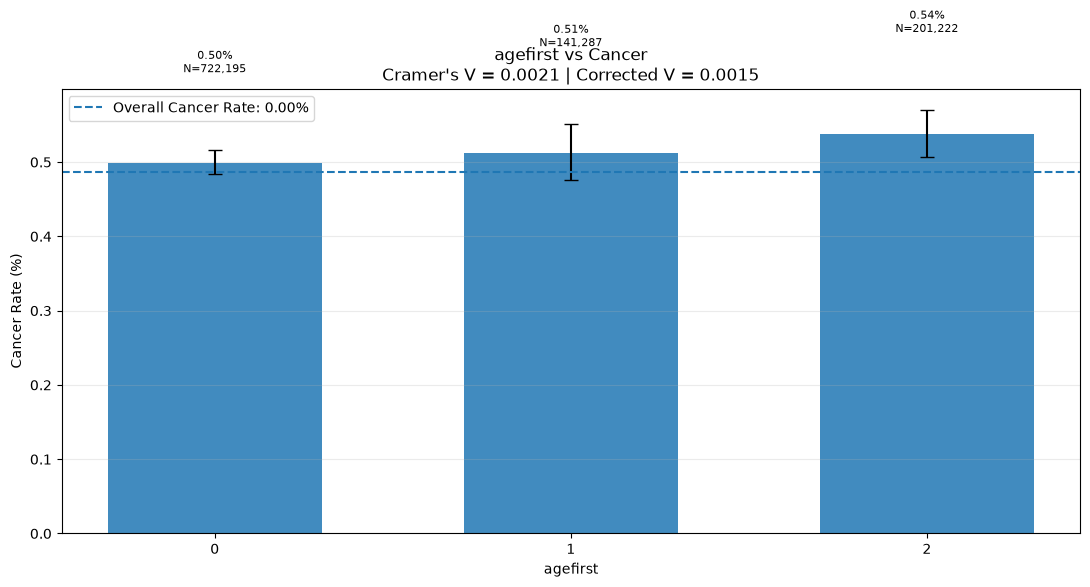


Analyzing: nrelbc
Cramer's V: 0.01075798601508677
Corrected Cramer's V: 0.010712093243625704
P-value: 9.803339937897296e-52
Excluded percentage: 15.183%

Category Statistics:
Category  No Cancer  Cancer   Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0    1710426    7934 1718360         0.461719      0.451693      0.471967
       1     293855    1913  295768         0.646791      0.618534      0.676329
       2      15408     143   15551         0.919555      0.781182      1.082171


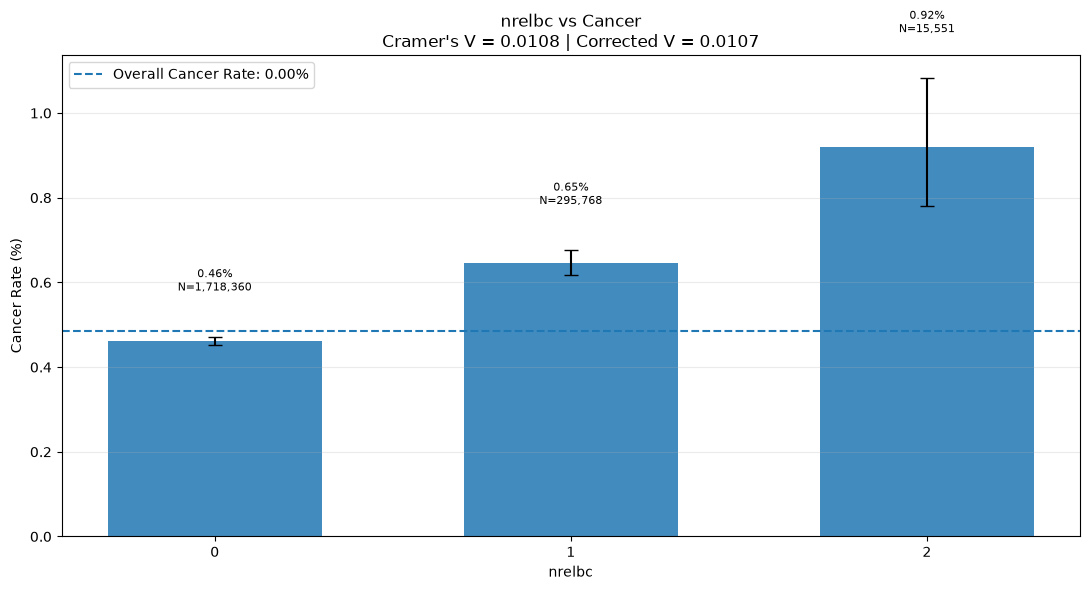


Analyzing: brstproc
Cramer's V: 0.01277203095642081
Corrected Cramer's V: 0.012753750291833281
P-value: 5.377005983319152e-78
Excluded percentage: 10.460%

Category Statistics:
Category  No Cancer  Cancer   Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0    1714642    7614 1722256         0.442095      0.432296      0.452114
       1     417631    2799  420430         0.665747      0.641612      0.690784


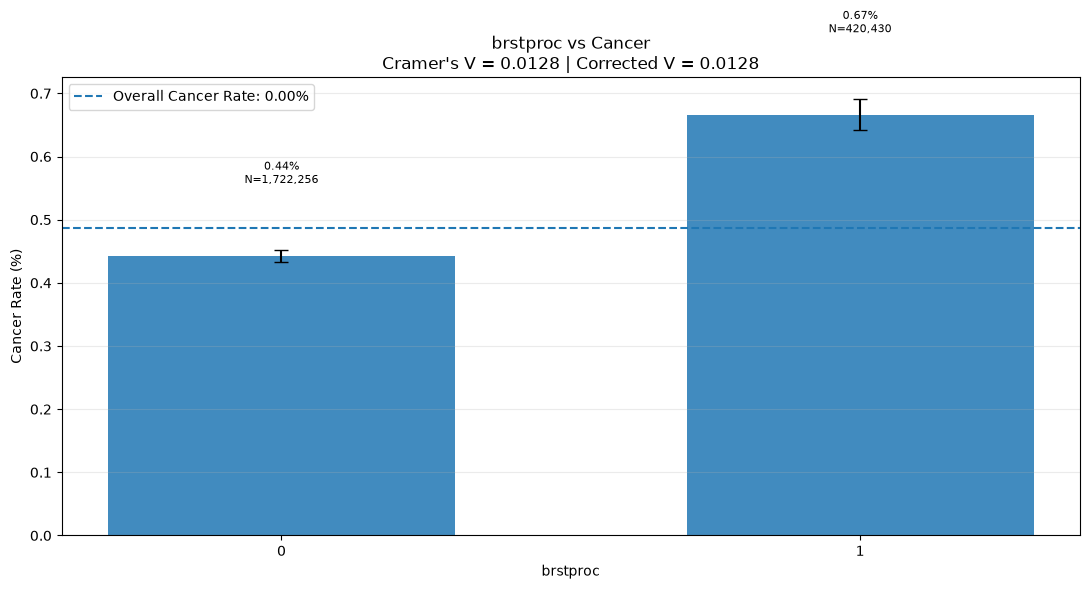


Analyzing: lastmamm
Cramer's V: 0.0060113153852055
Corrected Cramer's V: 0.005965791611576395
P-value: 3.9269122093395403e-16
Excluded percentage: 23.361%

Category Statistics:
Category  No Cancer  Cancer   Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0    1791368    8566 1799934         0.475906      0.465957      0.486067
       1      33779     267   34046         0.784233      0.695927      0.883644


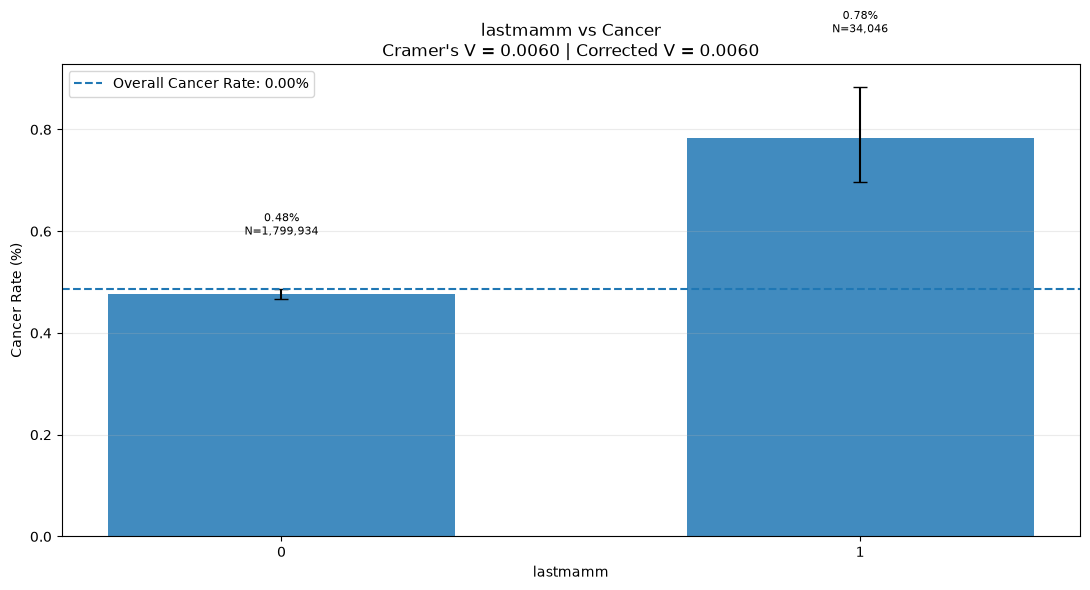


Analyzing: surgmeno
Cramer's V: 0.00586046589176461
Corrected Cramer's V: 0.00578549511539365
P-value: 3.569245563470654e-10
Excluded percentage: 52.140%

Category Statistics:
Category  No Cancer  Cancer  Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0     713650    4316 717966         0.601143      0.583524      0.619290
       1     425152    2180 427332         0.510142      0.489222      0.531952


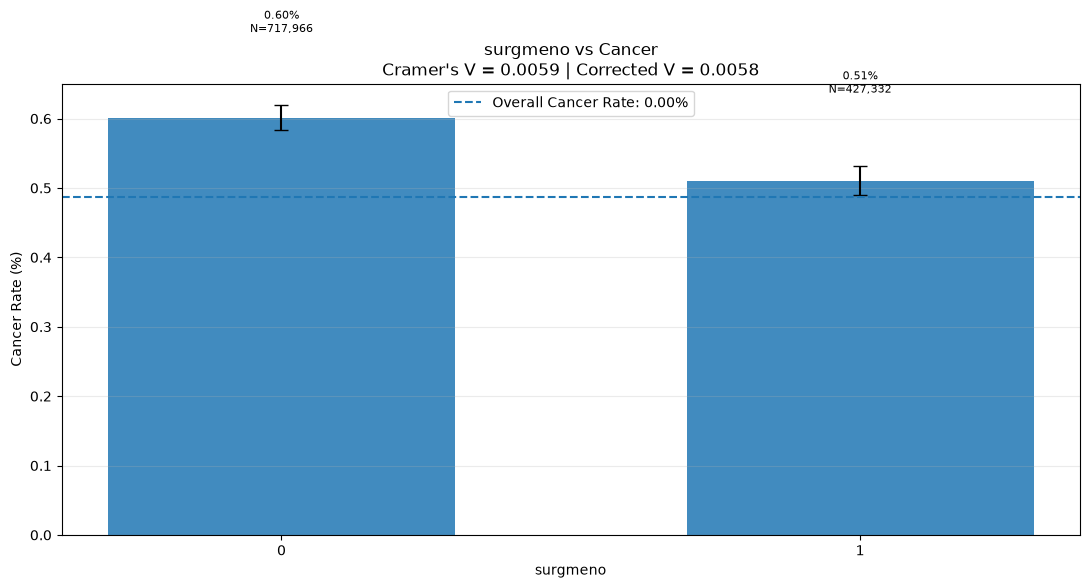


Analyzing: hrt
Cramer's V: 0.0021090492089305478
Corrected Cramer's V: 0.0019339465260537754
P-value: 0.012189264564521603
Excluded percentage: 40.972%

Category Statistics:
Category  No Cancer  Cancer  Total  Cancer Rate (%)  CI Lower (%)  CI Upper (%)
       0     725211    3985 729196         0.546492      0.529829      0.563676
       1     679400    3950 683350         0.578035      0.560336      0.596289


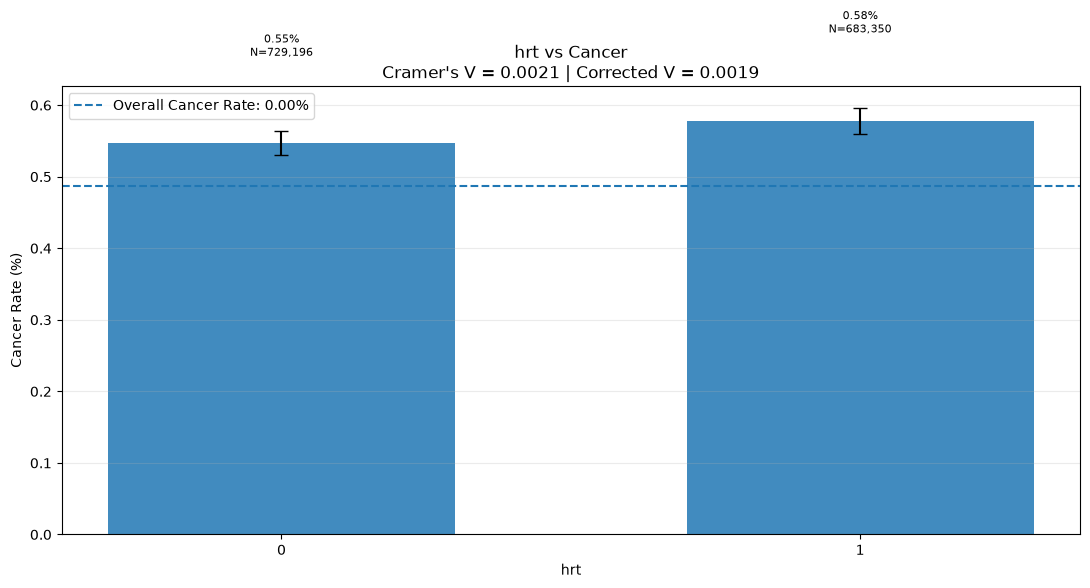

In [12]:
# Cell 5: Analyze every feature and save category-level results and plots

summary_results = []

for feature in FEATURES:
    print("\n" + "=" * 70)
    print(f"Analyzing: {feature}")
    print("=" * 70)

    numeric_feature = pd.to_numeric(df[feature], errors="coerce")
    if numeric_feature.notna().sum() == df[feature].notna().sum():
        analysis_feature = numeric_feature
    else:
        analysis_feature = df[feature]

    valid_mask = analysis_feature.notna() & (analysis_feature != UNKNOWN_CODE)
    feature_df = df.loc[valid_mask].copy()
    feature_df["_feature"] = analysis_feature.loc[valid_mask]

    excluded_weight = df.loc[~valid_mask, WEIGHT].sum()
    valid_weight = feature_df[WEIGHT].sum()
    excluded_percentage = excluded_weight / total_observations * 100

    if feature_df.empty:
        print("Skipped: no valid observations.")
        continue

    contingency = pd.pivot_table(
        feature_df,
        index="_feature",
        columns=TARGET,
        values=WEIGHT,
        aggfunc="sum",
        fill_value=0,
    ).reindex(columns=[0, 1], fill_value=0)
    contingency.columns = ["No Cancer", "Cancer"]
    contingency = contingency.loc[contingency.sum(axis=1) > 0]

    if contingency.shape[0] < 2:
        print("Skipped: fewer than two valid categories.")
        continue

    category_results = []
    for category in contingency.index:
        no_cancer = contingency.loc[category, "No Cancer"]
        cancer = contingency.loc[category, "Cancer"]
        total = no_cancer + cancer
        rate = cancer / total
        ci_lower, ci_upper = weighted_wilson_interval(cancer, total)

        category_results.append({
            "Category": str(category),
            "No Cancer": int(no_cancer),
            "Cancer": int(cancer),
            "Total": int(total),
            "Cancer Rate (%)": rate * 100,
            "CI Lower (%)": ci_lower * 100,
            "CI Upper (%)": ci_upper * 100,
        })

    category_table = pd.DataFrame(category_results)
    standard_v, p_value, corrected_v = calculate_cramers_v(contingency)

    print(f"Cramer's V: {standard_v}")
    print(f"Corrected Cramer's V: {corrected_v}")
    print(f"P-value: {p_value}")
    print(f"Excluded percentage: {excluded_percentage:.3f}%")
    print("\nCategory Statistics:")
    print(category_table.to_string(index=False))

    category_table.to_csv(
        OUTPUT_DIR / f"{feature}_cancer_rates.csv",
        index=False,
    )

    x = np.arange(len(category_table))
    rates = category_table["Cancer Rate (%)"].to_numpy()
    lower_errors = rates - category_table["CI Lower (%)"].to_numpy()
    upper_errors = category_table["CI Upper (%)"].to_numpy() - rates

    fig, ax = plt.subplots(figsize=(11, 6))
    bars = ax.bar(
        x,
        rates,
        width=0.6,
        alpha=0.85,
        yerr=[lower_errors, upper_errors],
        capsize=5,
    )
    ax.axhline(
        overall_cancer_rate * 100,
        linestyle="--",
        linewidth=1.5,
        label=f"Overall Cancer Rate: {overall_cancer_rate:.2f}%",
    )

    for index, bar in enumerate(bars):
        total = category_table.iloc[index]["Total"]
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            rates[index] + upper_errors[index] + 0.1,
            f"{rates[index]:.2f}%\nN={total:,}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(category_table["Category"].astype(str), rotation=0)
    ax.set_xlabel(feature)
    ax.set_ylabel("Cancer Rate (%)")
    ax.set_title(
        f"{feature} vs Cancer\n"
        f"Cramer's V = {standard_v:.4f} | Corrected V = {corrected_v:.4f}"
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"{feature}_vs_cancer.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    summary_results.append({
        "Feature": feature,
        "Cramers V": standard_v,
        "Corrected Cramers V": corrected_v,
        "P-value": p_value,
        "Valid Observations": int(valid_weight),
        "Excluded Observations": int(excluded_weight),
        "Excluded Percentage": excluded_percentage,
    })

In [13]:
# Cell 6: Rank features and save the final summary

summary = pd.DataFrame(summary_results)

if not summary.empty:
    summary = summary.sort_values("Corrected Cramers V", ascending=False)
    summary.to_csv(
        OUTPUT_DIR / "ALL_FEATURES_ASSOCIATION_SUMMARY.csv",
        index=False,
    )

    print("\n" + "=" * 70)
    print("FINAL FEATURE RANKING")
    print("=" * 70)
    print(summary.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
else:
    print("No valid feature results were generated.")

print("\nAnalysis completed.")
print(f"Results directory: {OUTPUT_DIR.resolve()}")


FINAL FEATURE RANKING
 Feature  Cramers V  Corrected Cramers V  P-value  Valid Observations  Excluded Observations  Excluded Percentage
  agegrp   0.024097             0.024023 0.000000             2247896                 145102             6.063607
menopaus   0.016274             0.016260 0.000000             2211039                 181959             7.603809
 density   0.013837             0.013775 0.000000             1740612                 652386            27.262288
brstproc   0.012772             0.012754 0.000000             2142686                 250312            10.460184
  nrelbc   0.010758             0.010712 0.000000             2029679                 363319            15.182587
lastmamm   0.006011             0.005966 0.000000             1833980                 559018            23.360571
surgmeno   0.005860             0.005785 0.000000             1145298                1247700            52.139617
Hispanic   0.005127             0.005075 0.000000             190